# Section 1 · Task 1.1 — Define Pauli Operators

**Exam:** C1000-179 *Fundamentals of Quantum Computing Using Qiskit v2.X Developer*
**Section 1:** Perform quantum operations (≈ 16 % of the exam) → **Task 1.1: Define Pauli Operators**
**Official reference from the study guide:** [`qiskit.quantum_info.Pauli`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Pauli)

---

### The study guide's own self-test
IBM asks you three questions about every objective. This notebook is built so you can answer *yes* to all three for Pauli operators:

1. **Do you know how** to define and manipulate a Pauli operator in Qiskit?
2. **Do you know why** you would — what are Paulis *for*?
3. **Do you know what happens if you do it incorrectly?** (wrong qubit order, wrong composition order, forgetting phases …)

### What you will be able to do afterwards
- State the algebra of $I, X, Y, Z$ from memory and verify it numerically
- Build `Pauli` objects four different ways and read their `z`/`x`/`phase` internals
- Predict the label ↔ matrix ↔ qubit-index mapping without running code (little-endian!)
- Use `compose` / `dot` / `tensor` / `expand` / `adjoint` correctly — and know which order each one multiplies in
- Decide whether two Paulis commute **by inspection**
- Use Paulis as observables, measurement bases, and a basis for decomposing operators

### How to work through it
Run top to bottom. Every exercise cell is a stub that returns `None` — the notebook runs fine without your answers, and each checker tells you whether you've attempted it yet. **Solutions are in the last section.** Try first.

In [1]:
import warnings
import numpy as np
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import (
    Pauli, PauliList, SparsePauliOp, Operator, Statevector, Clifford, random_pauli
)

np.set_printoptions(precision=3, suppress=True)
print("qiskit", qiskit.__version__)

def _todo(name):
    print(f"⏳ {name}: not attempted yet — fill in the TODO above and re-run this cell.")

qiskit 2.6.1


---
## 1 · The mathematics (before any Qiskit)

The four **Pauli matrices** are

$$
I=\begin{pmatrix}1&0\\0&1\end{pmatrix},\quad
X=\begin{pmatrix}0&1\\1&0\end{pmatrix},\quad
Y=\begin{pmatrix}0&-i\\ i&0\end{pmatrix},\quad
Z=\begin{pmatrix}1&0\\0&-1\end{pmatrix}.
$$

### Properties you must know cold
| Property | Statement | Why it matters |
|---|---|---|
| Hermitian | $P^\dagger = P$ | They are valid **observables** (real measurement outcomes) |
| Unitary | $P^\dagger P = I$ | They are valid **gates** |
| Involutory | $P^2 = I$ | Each is its own inverse |
| Eigenvalues | $\pm 1$ (for $X,Y,Z$) | A Pauli measurement always returns $+1$ or $-1$ |
| Traceless | $\operatorname{Tr}X=\operatorname{Tr}Y=\operatorname{Tr}Z=0$ | Makes them an *orthogonal* basis together with $I$ |
| Anticommute | $XY=-YX$, $YZ=-ZY$, $ZX=-XZ$ | Source of uncertainty relations and of the commutation rules in §5 |
| Cyclic products | $XY=iZ,\; YZ=iX,\; ZX=iY$ | Products stay *inside* the Pauli group, up to a phase in $\{\pm1,\pm i\}$ |

For $n$ qubits, an **$n$-qubit Pauli operator** is a tensor product of $n$ single-qubit Paulis, e.g. $X\otimes Z\otimes I$, times a phase in $\{1,-i,-1,i\}$. There are $4^n$ of them (ignoring phase).

Let's verify the single-qubit facts numerically — building habits of *checking* rather than trusting.

In [2]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
paulis = {"I": I2, "X": X, "Y": Y, "Z": Z}

for name, M in paulis.items():
    hermitian = np.allclose(M, M.conj().T)
    unitary   = np.allclose(M @ M.conj().T, I2)
    squares_to_I = np.allclose(M @ M, I2)
    eig = np.round(np.linalg.eigvalsh(M), 6)          # eigvalsh: valid because M is Hermitian
    print(f"{name}: hermitian={hermitian}  unitary={unitary}  P²=I:{squares_to_I}  "
          f"trace={np.trace(M).real:+.0f}  eigenvalues={eig}")

I: hermitian=True  unitary=True  P²=I:True  trace=+2  eigenvalues=[1. 1.]
X: hermitian=True  unitary=True  P²=I:True  trace=+0  eigenvalues=[-1.  1.]
Y: hermitian=True  unitary=True  P²=I:True  trace=+0  eigenvalues=[-1.  1.]
Z: hermitian=True  unitary=True  P²=I:True  trace=+0  eigenvalues=[-1.  1.]


In [3]:
# Anticommutation:  PQ + QP = 0  for distinct non-identity Paulis
for a, b in [("X", "Y"), ("Y", "Z"), ("Z", "X")]:
    A, B = paulis[a], paulis[b]
    print(f"{a}{b} + {b}{a} = 0 ?", np.allclose(A @ B + B @ A, 0),
          f"| {a}{b} == i·{ {'XY':'Z','YZ':'X','ZX':'Y'}[a+b] } ?",
          np.allclose(A @ B, 1j * paulis[{'XY':'Z','YZ':'X','ZX':'Y'}[a+b]]))

XY + YX = 0 ? True | XY == i·Z ? True
YZ + ZY = 0 ? True | YZ == i·X ? True
ZX + XZ = 0 ? True | ZX == i·Y ? True


### A product table you can *compute* instead of memorise
The helper below takes any 2×2 matrix that is a phase times a Pauli and tells you which one. It is also a nice preview of why Paulis are a **group**: every product lands back in the set.

In [4]:
def identify(M):
    # Return (phase, label) such that M == phase * Pauli_label, or None.
    for label, P in paulis.items():
        for phase, pname in [(1, "+1"), (-1, "-1"), (1j, "+i"), (-1j, "-i")]:
            if np.allclose(M, phase * P):
                return pname, label
    return None

labels = ["I", "X", "Y", "Z"]
print("row·col  |  " + "    ".join(f"{c:>4}" for c in labels))
print("-" * 36)
for r in labels:
    row = []
    for c in labels:
        ph, lab = identify(paulis[r] @ paulis[c])
        row.append(f"{ph}{lab}".rjust(4))
    print(f"   {r}     |  " + "    ".join(row))

row·col  |     I       X       Y       Z
------------------------------------
   I     |   +1I     +1X     +1Y     +1Z
   X     |   +1X     +1I     +iZ     -iY
   Y     |   +1Y     -iZ     +1I     +iX
   Z     |   +1Z     +iY     -iX     +1I


Read it row-first: row **X**, column **Y** is `+iZ`, i.e. $XY = iZ$. Row **Y**, column **X** is `-iZ`, i.e. $YX=-iZ$. The *order of multiplication matters* — keep that in mind, because Qiskit has **two** product methods (`dot` and `compose`) that differ exactly by this order.

---
## 2 · The `Pauli` class — four ways to construct one

`qiskit.quantum_info.Pauli` represents an **n-qubit Pauli operator including its phase**. It does *not* store a $2^n\times 2^n$ matrix; it stores two bit-vectors (§3), so a 1000-qubit Pauli is cheap. The matrix is only built on demand with `.to_matrix()`.

### 2.1 From a label string (the one you'll use 95 % of the time)

In [5]:
p = Pauli("XYZ")
print("object        :", repr(p))
print("label         :", p.to_label())
print("num_qubits    :", p.num_qubits, "  len():", len(p))
print("matrix shape  :", p.to_matrix().shape, " (2^3 x 2^3)")

# Phase prefixes are part of the label:  '', '-', 'i', '-i'
for lab in ["X", "-X", "iX", "-iX"]:
    print(f"{lab:>4} ->", repr(Pauli(lab)))

object        : Pauli('XYZ')
label         : XYZ
num_qubits    : 3   len(): 3
matrix shape  : (8, 8)  (2^3 x 2^3)
   X -> Pauli('X')
  -X -> Pauli('-X')
  iX -> Pauli('iX')
 -iX -> Pauli('-iX')


### 2.2 From the symplectic `(z, x)` bit-arrays
A Pauli is fully described by two boolean arrays `z` and `x` (plus a phase). Per qubit: `(z,x) = (0,0)→I`, `(0,1)→X`, `(1,0)→Z`, `(1,1)→Y`.

### 2.3 From other objects
`Pauli(...)` also accepts an existing `Pauli` (copy), and `random_pauli(n, seed=…)` gives a random one. We'll use `random_pauli` for stress-testing identities.

In [6]:
# Build from (z, x). Remember arrays are indexed by QUBIT, so index 0 = qubit 0 = RIGHTMOST label character.
z = np.array([True, False, True])    # z[0]=1 (qubit 0), z[1]=0, z[2]=1
x = np.array([False, True, True])    # x[0]=0,           x[1]=1, x[2]=1
p_from_arrays = Pauli((z, x))
print("from (z,x):", p_from_arrays, "  <- qubit2:(z=1,x=1)=Y, qubit1:(0,1)=X, qubit0:(1,0)=Z")

# From an existing object / random
print("copy       :", Pauli(p_from_arrays))
print("random(3)  :", random_pauli(3, seed=7))

from (z,x): YXZ   <- qubit2:(z=1,x=1)=Y, qubit1:(0,1)=X, qubit0:(1,0)=Z
copy       : YXZ
random(3)  : IZY


### 2.4 Indexing and slicing → sub-Paulis
Indexing uses **qubit indices**, so `p[0]` is the *rightmost* character.

In [7]:
p = Pauli("IXZ")          # qubit2=I, qubit1=X, qubit0=Z
print("p[0]       :", p[0])        # -> Z   (qubit 0)
print("p[1]       :", p[1])        # -> X
print("p[2]       :", p[2])        # -> I
print("p[[0, 2]]  :", p[[0, 2]])   # list of qubit indices, returned in the order requested
print("p[0:2]     :", p[0:2])      # slice -> qubits 0 and 1 -> 'XZ'
print("p.delete(0):", p.delete(0), "   p.insert(1, Pauli('Y')):", p.insert(1, Pauli("Y")))

p[0]       : Z
p[1]       : X
p[2]       : I
p[[0, 2]]  : IZ
p[0:2]     : XZ
p.delete(0): IX    p.insert(1, Pauli('Y')): IXYZ


---
## 3 · Label order, qubit order, and the internal `z / x / phase` representation

### 3.1 The little-endian rule
> **The rightmost character of a Pauli label acts on qubit 0.**

So `Pauli("XZ")` is $X$ on qubit 1 and $Z$ on qubit 0, and its matrix is the Kronecker product with the **leftmost label character as the leftmost Kronecker factor**:

$$\texttt{Pauli("XZ")}\;\longrightarrow\; X\otimes Z .$$

(Because qubit 1 is the more significant bit in Qiskit's basis ordering $|q_1q_0\rangle$, it belongs on the left of the Kronecker product.) Verify:

In [8]:
print("Pauli('XZ') == X ⊗ Z ?", np.allclose(Pauli("XZ").to_matrix(), np.kron(X, Z)))
print("Pauli('XZ') == Z ⊗ X ?", np.allclose(Pauli("XZ").to_matrix(), np.kron(Z, X)), " <- the classic mistake")

# Which qubit does each character act on?  Check by applying Pauli('XI') and Pauli('IX') to |00>.
for lab in ["XI", "IX"]:
    out = Statevector.from_label("00").evolve(Pauli(lab))
    print(f"Pauli('{lab}') |00>  ->", out.probabilities_dict())
# 'IX' flips qubit 0 -> basis string '01' (qubit0 is the rightmost bit).  'XI' flips qubit 1 -> '10'.

Pauli('XZ') == X ⊗ Z ? True
Pauli('XZ') == Z ⊗ X ? False  <- the classic mistake
Pauli('XI') |00>  -> {np.str_('10'): np.float64(1.0)}
Pauli('IX') |00>  -> {np.str_('01'): np.float64(1.0)}


### 3.2 What is inside: `z`, `x`, and `phase`
Qiskit stores an $n$-qubit Pauli as

$$P \;=\; (-i)^{\,q}\; Z^{\mathbf z}\,X^{\mathbf x},\qquad q=\texttt{phase} + \textstyle\sum_k z_k x_k ,$$

where $Z^{\mathbf z}X^{\mathbf x}$ means "tensor product over qubits of $Z^{z_k}X^{x_k}$".

Two things to notice:
- A **Y** has `z=1, x=1`. Since $ZX = iY$, we get $Y=(-i)\,ZX$ — so that hidden factor $(-i)$ is accounted for by the $\sum z_kx_k$ term. That is why **`Pauli("Y").phase == 0`** even though $Y\neq ZX$.
- `phase` counts powers of $-i$ **in addition to** the Y-bookkeeping: `-iX → 1`, `-X → 2`, `iX → 3`.

Let's check the formula against `to_matrix()` on random 3-qubit Paulis (including random phases).

In [9]:
def rebuild_matrix(p):
    # Rebuild a Pauli matrix from (z, x, phase) using only the formula above.
    nq = p.num_qubits
    q = (p.phase + int(np.sum(p.z & p.x))) % 4
    M = np.array([[1.0 + 0j]])
    for k in reversed(range(nq)):                 # qubit n-1 is the leftmost Kronecker factor
        factor = np.linalg.matrix_power(Z, int(p.z[k])) @ np.linalg.matrix_power(X, int(p.x[k]))
        M = np.kron(M, factor)
    return (-1j) ** q * M

rng_ok = True
for seed in range(20):
    p = random_pauli(3, group_phase=True, seed=seed)     # group_phase=True -> random phase in {1,-i,-1,i}
    rng_ok &= np.allclose(rebuild_matrix(p), p.to_matrix())
print("formula reproduces to_matrix() on 20 random 3-qubit Paulis:", rng_ok)

for lab in ["I", "X", "Y", "Z", "-Y", "iZ"]:
    p = Pauli(lab)
    print(f"{lab:>3}: z={p.z}, x={p.x}, phase={p.phase}")

formula reproduces to_matrix() on 20 random 3-qubit Paulis: True
  I: z=[False], x=[False], phase=0
  X: z=[False], x=[ True], phase=0
  Y: z=[ True], x=[ True], phase=0
  Z: z=[ True], x=[False], phase=0
 -Y: z=[ True], x=[ True], phase=2
 iZ: z=[ True], x=[False], phase=3


**Exam takeaway:** `z` and `x` are the *symplectic* representation; `phase` is a *group phase exponent* ($(-i)^{\text{phase}}$ with the Y-correction already taken out). You will rarely need to touch them, but you may be shown them and asked which label they encode.

---
## 4 · Pauli algebra in Qiskit: products, tensors, adjoints

### 4.1 Two product methods — and the order trap

| Call | Matrix product | Meaning |
|---|---|---|
| `A.dot(B)` &nbsp;(also `A @ B`) | $A\cdot B$ | apply $B$ first, then $A$ (standard math order) |
| `A.compose(B)` | $B\cdot A$ | apply $A$ first, then $B$ (**circuit** order) |

`compose` follows the convention used for circuits and `Operator.compose`: "A, then B". `dot` follows ordinary matrix multiplication. For commuting Paulis they agree; for anticommuting ones they differ by a sign.

In [10]:
A, B = Pauli("X"), Pauli("Y")
print("A.dot(B)     =", A.dot(B), "  (X·Y = iZ)")
print("A @ B        =", A @ B)
print("A.compose(B) =", A.compose(B), "  (Y·X = -iZ)   <- note the sign flip")

# Cross-check against raw matrices
print(np.allclose(A.dot(B).to_matrix(),     X @ Y),
      np.allclose(A.compose(B).to_matrix(), Y @ X))

A.dot(B)     = iZ   (X·Y = iZ)
A @ B        = iZ
A.compose(B) = -iZ   (Y·X = -iZ)   <- note the sign flip
True True


Multi-qubit products multiply **qubit-by-qubit** and collect the phases:

In [11]:
P, Q = Pauli("XYZ"), Pauli("ZZX")
prod = P.dot(Q)
print(f"{P} · {Q} = {prod}")
# By hand, qubit by qubit (left to right): X·Z = -iY, Y·Z = iX, Z·X = iY  -> phase (-i)(i)(i) = i ... Qiskit says:
print("matches raw matrix product:", np.allclose(prod.to_matrix(), P.to_matrix() @ Q.to_matrix()))

# compose on a subset of qubits:  qargs says WHICH qubits of P the (smaller) operator acts on
print("Pauli('XYZ').compose(Pauli('ZZ'), qargs=[0,1]) =", Pauli("XYZ").compose(Pauli("ZZ"), qargs=[0, 1]))

XYZ · ZZX = iYXY
matches raw matrix product: True
Pauli('XYZ').compose(Pauli('ZZ'), qargs=[0,1]) = -iXXI


### 4.2 `tensor` vs `expand` — another order trap

| Call | Result | Label |
|---|---|---|
| `A.tensor(B)` &nbsp;(also `A ^ B`) | $A\otimes B$ | `A` is on the **higher** qubits (left in label) |
| `A.expand(B)` | $B\otimes A$ | `A` stays on the **lower** qubits (right in label) |

In [12]:
A, B = Pauli("X"), Pauli("Z")
print("A.tensor(B) =", A.tensor(B), "| A ^ B =", A ^ B, "   (X ⊗ Z)")
print("A.expand(B) =", A.expand(B), "                  (Z ⊗ X)")

A.tensor(B) = XZ | A ^ B = XZ    (X ⊗ Z)
A.expand(B) = ZX                   (Z ⊗ X)


### 4.3 Phase, scalar multiplication, adjoint, conjugate, transpose
- A Pauli can be multiplied by a **phase in $\{\pm1,\pm i\}$** (`-1j * P`, `-P`). Any other scalar is *not* a Pauli and raises an error — use `SparsePauliOp` for general coefficients.
- `*` between two Paulis is **not** matrix multiplication — it is scalar multiplication only. Use `dot`/`compose`/`@`.
- Since $P^\dagger=P$ for the *unphased* Pauli, `adjoint()` only conjugates the phase: $(iP)^\dagger = -iP$.

In [13]:
P = Pauli("XYZ")
print("-1j * P         :", -1j * P)
print("-P              :", -P)
print("(iP).adjoint()  :", (1j * P).adjoint(), "   (phase conjugated)")
print("P.adjoint()     :", P.adjoint(), "  (Hermitian: unchanged)")
print("(iY).transpose():", Pauli("iY").transpose(), "  (Y^T = -Y, so the transpose flips the sign)")
print("(iX).conjugate():", Pauli("iX").conjugate())

try:
    Pauli("X") * Pauli("Z")           # NOT how you multiply two Paulis
except Exception as e:
    print("\nPauli('X') * Pauli('Z') ->", type(e).__name__, "(use .dot / @ instead)")

try:
    0.5 * Pauli("X")                  # not a valid Pauli phase
except Exception as e:
    print("0.5 * Pauli('X')        ->", type(e).__name__, ":", str(e)[:70], "...")

-1j * P         : -iXYZ
-P              : -XYZ
(iP).adjoint()  : -iXYZ    (phase conjugated)
P.adjoint()     : XYZ   (Hermitian: unchanged)
(iY).transpose(): -iY   (Y^T = -Y, so the transpose flips the sign)
(iX).conjugate(): -iX

Pauli('X') * Pauli('Z') -> ValueError (use .dot / @ instead)
0.5 * Pauli('X')        -> QiskitError : 'Pauli can only be multiplied by 1, -1j, -1, 1j.' ...


### 4.4 Equality: `==` vs `.equiv()`
`==` compares **z, x and phase**; `.equiv()` compares the Pauli *up to phase* (are they the "same Pauli string"?). That distinction matters because `Y` and `-Y` are different operators but the same Pauli string.

In [14]:
print("Pauli('Y') == Pauli('-Y')       :", Pauli("Y") == Pauli("-Y"))
print("Pauli('Y').equiv(Pauli('-Y'))   :", Pauli("Y").equiv(Pauli("-Y")))
print("Pauli('Y').equiv(Pauli('X'))    :", Pauli("Y").equiv(Pauli("X")))

Pauli('Y') == Pauli('-Y')       : False
Pauli('Y').equiv(Pauli('-Y'))   : True
Pauli('Y').equiv(Pauli('X'))    : False


---
## 5 · Commutation — decide by inspection

Two $n$-qubit Paulis either **commute** ($PQ=QP$) or **anticommute** ($PQ=-QP$); there is no third option.

> **Rule.** Compare the two strings position by position. Count positions where both characters are *non-identity and different* (e.g. $X$ vs $Z$). If that count is **even** → the Paulis **commute**. If **odd** → they **anticommute**.

Single-qubit reason: distinct non-identity Paulis anticommute; each such position contributes one factor of $-1$. So `XZ` vs `ZX` has **two** clashing positions → $(-1)^2=+1$ → they commute, even though neither position commutes on its own.

In [15]:
def clashes(a, b):
    # number of positions where the two single-qubit Paulis are both non-identity and different
    return sum(1 for s, t in zip(a, b) if s != "I" and t != "I" and s != t)

pairs = [("XZ", "ZX"), ("XX", "ZZ"), ("XI", "ZI"), ("XYZ", "ZYX"), ("XX", "XI"), ("YY", "ZZ")]
print(f"{'P':>4} {'Q':>4} | clashes | Qiskit commutes? | matrix check")
for a, b in pairs:
    P, Q = Pauli(a), Pauli(b)
    mA, mB = P.to_matrix(), Q.to_matrix()
    brute = np.allclose(mA @ mB, mB @ mA)
    print(f"{a:>4} {b:>4} |   {clashes(a, b)}     |      {str(P.commutes(Q)):<5}       | {brute}")

   P    Q | clashes | Qiskit commutes? | matrix check
  XZ   ZX |   2     |      True        | True
  XX   ZZ |   2     |      True        | True
  XI   ZI |   1     |      False       | False
 XYZ  ZYX |   2     |      True        | True
  XX   XI |   0     |      True        | True
  YY   ZZ |   2     |      True        | True


`commutes()` and `anticommutes()` also accept `qargs=` when one Pauli is shorter than the other (like `compose`), and `PauliList` can test many at once.

In [16]:
big = Pauli("XXI")                       # qubit2=X, qubit1=X, qubit0=I
small = Pauli("ZZ")                      # act with Z on qubits [0,1] of `big`
print("XXI vs ZZ on qubits [0,1] commute?", big.commutes(small, qargs=[0, 1]))   # q1: X vs Z clash -> odd -> False

pl = PauliList(["XX", "ZZ", "YY", "ZI", "XZ"])
print("which of", pl.to_labels(), "commute with XX ->", pl.commutes(Pauli("XX")))

XXI vs ZZ on qubits [0,1] commute? False
which of ['XX', 'ZZ', 'YY', 'ZI', 'XZ'] commute with XX -> [ True  True  True False False]


### Why commutation matters (you will meet this again in Sections 5–6)
- Paulis that **commute** can be measured **simultaneously** — this is how `Estimator` groups terms of an observable.
- A **stabilizer state** is the joint $+1$ eigenstate of a set of mutually commuting Paulis. The Bell state $|\Phi^+\rangle$ is stabilised by `XX` and `ZZ`:

In [17]:
bell = QuantumCircuit(2); bell.h(0); bell.cx(0, 1)
sv = Statevector(bell)
print("Bell state:", sv.data.round(3))
for lab in ["XX", "ZZ", "YY", "XZ", "ZI", "IZ"]:
    print(f"<{lab}> = {sv.expectation_value(Pauli(lab)).real:+.3f}")
print("\nXX and ZZ commute:", Pauli('XX').commutes(Pauli('ZZ')),
      "→ both have a definite value (+1,+1) in |Φ+>.  YY = -XX·ZZ → -1 follows automatically.")
print("check  XX·ZZ =", Pauli('XX').dot(Pauli('ZZ')), "  (= -YY)")

Bell state: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]
<XX> = +1.000
<ZZ> = +1.000
<YY> = -1.000
<XZ> = +0.000
<ZI> = +0.000
<IZ> = +0.000

XX and ZZ commute: True → both have a definite value (+1,+1) in |Φ+>.  YY = -XX·ZZ → -1 follows automatically.
check  XX·ZZ = -YY   (= -YY)


---
## 6 · Paulis as measurements: eigenbases and basis change

Each of $X,Y,Z$ has two eigenvectors (eigenvalues $\pm1$):

| Pauli | $+1$ eigenstate | $-1$ eigenstate | Qiskit labels |
|---|---|---|---|
| $Z$ | $\lvert0\rangle$ | $\lvert1\rangle$ | `"0"`, `"1"` |
| $X$ | $\lvert+\rangle=\frac{\lvert0\rangle+\lvert1\rangle}{\sqrt2}$ | $\lvert-\rangle$ | `"+"`, `"-"` |
| $Y$ | $\lvert{+i}\rangle=\frac{\lvert0\rangle+i\lvert1\rangle}{\sqrt2}$ | $\lvert{-i}\rangle$ | `"r"`, `"l"` |

Hardware can only measure in the **Z basis**. To measure Pauli $P$ you rotate $P$'s eigenbasis onto Z, then measure Z:

| Measure | Apply before the Z-measurement |
|---|---|
| $Z$ | nothing |
| $X$ | `H` |
| $Y$ | `Sdg` then `H` |

Born rule link: $\Pr(\pm1)=\tfrac{1\pm\langle P\rangle}{2}$. Let's confirm numerically for several states.

In [18]:
# Eigenstates + eigenvalues
for lab, P in [("0", "Z"), ("1", "Z"), ("+", "X"), ("-", "X"), ("r", "Y"), ("l", "Y")]:
    ev = Statevector.from_label(lab).expectation_value(Pauli(P)).real
    print(f"|{lab}> is an eigenstate of {P} with eigenvalue {ev:+.0f}")

|0> is an eigenstate of Z with eigenvalue +1
|1> is an eigenstate of Z with eigenvalue -1
|+> is an eigenstate of X with eigenvalue +1
|-> is an eigenstate of X with eigenvalue -1
|r> is an eigenstate of Y with eigenvalue +1
|l> is an eigenstate of Y with eigenvalue -1


In [19]:
def basis_change(pauli_char):
    # circuit that rotates the eigenbasis of the given single-qubit Pauli onto the Z basis
    qc = QuantumCircuit(1)
    if pauli_char == "X":
        qc.h(0)
    elif pauli_char == "Y":
        qc.sdg(0); qc.h(0)
    return qc

# an arbitrary test state
test = QuantumCircuit(1); test.ry(0.9, 0); test.rz(0.4, 0)
psi = Statevector(test)

for P in "XYZ":
    expval = psi.expectation_value(Pauli(P)).real
    rotated = psi.evolve(basis_change(P))
    p0 = rotated.probabilities()[0]
    print(f"{P}: <{P}> = {expval:+.4f}   Pr(+1) from formula = {(1+expval)/2:.4f}   "
          f"Pr(outcome 0) after basis change = {p0:.4f}")

X: <X> = +0.7215   Pr(+1) from formula = 0.8607   Pr(outcome 0) after basis change = 0.8607
Y: <Y> = +0.3050   Pr(+1) from formula = 0.6525   Pr(outcome 0) after basis change = 0.6525
Z: <Z> = +0.6216   Pr(+1) from formula = 0.8108   Pr(outcome 0) after basis change = 0.8108


The last two numbers agree for all three — measuring *after* `basis_change(P)` in Z is the same as measuring $P$.

---
## 7 · Paulis as a basis: decomposing any operator

The $4^n$ Pauli strings are **orthogonal** under the Hilbert–Schmidt inner product, so *every* $2^n\times2^n$ matrix $M$ has a unique expansion

$$M=\sum_{P}c_P\,P,\qquad c_P=\frac{\operatorname{Tr}(P\,M)}{2^n}.$$

- If $M$ is **Hermitian**, all $c_P$ are **real**. (This is why every observable is a real combination of Pauli strings — and why `SparsePauliOp` is the standard observable type for `Estimator`.)
- `SparsePauliOp.from_operator` does the decomposition for you and drops zero terms.

In [20]:
M = np.array([[2, 1 - 1j],
              [1 + 1j, 0]])           # Hermitian
# Manual formula
manual = {l: np.trace(paulis[l] @ M) / 2 for l in "IXYZ"}
print("manual c_P:", {k: np.round(v, 3) for k, v in manual.items()})

# Qiskit
sp = SparsePauliOp.from_operator(Operator(M))
print(sp)
print("reconstructs M:", np.allclose(sp.to_matrix(), M))

manual c_P: {'I': np.complex128(1+0j), 'X': np.complex128(1+0j), 'Y': np.complex128(1+0j), 'Z': np.complex128(1+0j)}
SparsePauliOp(['I', 'X', 'Y', 'Z'],
              coeffs=[1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j])
reconstructs M: True


In [21]:
# Two-qubit example: H = ZZ + 0.5 XI  (an Ising-like Hamiltonian) -> matrix -> back to Paulis
H = SparsePauliOp(["ZZ", "XI"], coeffs=[1.0, 0.5])
H_matrix = H.to_matrix()
print("matrix is Hermitian:", np.allclose(H_matrix, H_matrix.conj().T))
print("decomposed back    :", SparsePauliOp.from_operator(Operator(H_matrix)).simplify())
print("number of possible Pauli strings on 2 qubits:", 4**2)

matrix is Hermitian: True
decomposed back    : SparsePauliOp(['XI', 'ZZ'],
              coeffs=[0.5+0.j, 1. +0.j])
number of possible Pauli strings on 2 qubits: 16


---
## 8 · Paulis acting on states and inside circuits

### 8.1 Directly on a `Statevector`
`Statevector.evolve(Pauli)` applies the operator (including phase) to the state.

In [22]:
sv = Statevector.from_label("00")
print("X on qubit 1, Z on qubit 0 applied to |00>:", sv.evolve(Pauli("XZ")).probabilities_dict())
print("Pauli('iX') |0>  =", Statevector.from_label("0").evolve(Pauli("iX")).data.round(3), " <- the phase shows up in the amplitude")

X on qubit 1, Z on qubit 0 applied to |00>: {np.str_('10'): np.float64(1.0)}
Pauli('iX') |0>  = [0.+0.j 0.+1.j]  <- the phase shows up in the amplitude


### 8.2 As a gate in a `QuantumCircuit`
A `Pauli` can be appended to a circuit directly — Qiskit wraps it in a `PauliGate` (the instruction name is `"pauli"`). This applies the *whole string at once*, including the right qubit mapping.

instruction name: pauli
same unitary as z(0), y(1), x(2): True


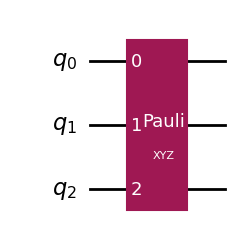

In [23]:
qc = QuantumCircuit(3)
qc.append(Pauli("XYZ"), [0, 1, 2])         # label char -> qubit: Z on q0, Y on q1, X on q2
print("instruction name:", qc.data[0].operation.name)

# equivalent explicit version
qc_explicit = QuantumCircuit(3)
qc_explicit.z(0); qc_explicit.y(1); qc_explicit.x(2)
print("same unitary as z(0), y(1), x(2):", Operator(qc).equiv(Operator(qc_explicit)))
qc.draw("mpl")

### 8.3 Paulis as *generators* of rotations
$R_P(\theta)=e^{-i\theta P/2}$ for any Pauli string $P$. That is how `RX`, `RY`, `RZ` are defined, and `PauliEvolutionGate(P, time=t)` implements $e^{-itP}$ (note the **$t=\theta/2$** relationship).

In [24]:
from scipy.linalg import expm
from qiskit.circuit.library import PauliEvolutionGate, RXGate, RZZGate

from scipy.sparse import SparseEfficiencyWarning
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)   # harmless scipy chatter from PauliEvolutionGate
theta = 0.7
print("RX(θ) == expm(-iθX/2)              :", np.allclose(RXGate(theta).to_matrix(), expm(-1j * theta * X / 2)))
print("PauliEvolutionGate(X, θ/2) == RX(θ):", np.allclose(Operator(PauliEvolutionGate(Pauli("X"), time=theta / 2)).data,
                                                         RXGate(theta).to_matrix()))
print("RZZ(θ) == expm(-iθ ZZ/2)            :", np.allclose(RZZGate(theta).to_matrix(),
                                                           expm(-1j * theta * Pauli("ZZ").to_matrix() / 2)))

RX(θ) == expm(-iθX/2)              : True
PauliEvolutionGate(X, θ/2) == RX(θ): True
RZZ(θ) == expm(-iθ ZZ/2)            : True


---
## 9 · Where `Pauli` sits among its relatives

| Class | Holds | Typical use |
|---|---|---|
| `Pauli` | **one** n-qubit Pauli string with a phase in $\{\pm1,\pm i\}$ | exact algebra, commutation, stabilisers |
| `PauliList` | a **list** of Pauli strings | vectorised commute-checks, grouping measurements |
| `SparsePauliOp` | a **weighted sum** of Pauli strings (arbitrary complex coefficients) | observables / Hamiltonians for `Estimator` (Section 6 of the exam) |
| `Clifford` | an operator that **maps Paulis to Paulis** | stabiliser simulation; `Pauli.evolve(Clifford)` |

`Pauli.evolve(C)` conjugates a Pauli by a Clifford (Heisenberg picture) and always returns another Pauli — that is what makes Cliffords special. Try it: a Hadamard swaps $X\leftrightarrow Z$ and sends $Y\to -Y$.

In [25]:
h = QuantumCircuit(1); h.h(0)
Ch = Clifford(h)
for lab in "XYZ":
    print(f"H conjugates {lab} -> {Pauli(lab).evolve(Ch)}")

H conjugates X -> Z
H conjugates Y -> -Y
H conjugates Z -> X


---
## 10 · Gotchas checklist (what goes wrong "if you do it incorrectly")

1. **Reading labels left-to-right as qubit 0, 1, 2…** → wrong. Rightmost char = qubit 0. `Pauli("XI")` flips *qubit 1*.
2. **`dot` vs `compose`.** `A.dot(B)` is $AB$; `A.compose(B)` is $BA$. For `X`,`Y` that is the difference between `iZ` and `-iZ`.
3. **`tensor` vs `expand`.** `A.tensor(B)` = $A\otimes B$ (A on the higher qubits); `A.expand(B)` = $B\otimes A$.
4. **`A * B` is not a product of Paulis** (it is scalar multiplication) — use `@` / `dot`.
5. **Only phases $\pm1,\pm i$** may multiply a `Pauli`; other coefficients need `SparsePauliOp`.
6. **`Y` has `phase == 0`** although $Y\neq ZX$ — the $(-i)$ is bundled into the `z&x` term.
7. **`==` vs `.equiv()`** — `Y == -Y` is `False`, `Y.equiv(-Y)` is `True`.
8. **Commutation by counting clashes:** *even* number of clashing positions → commute (`XZ` and `ZX` commute!).
9. **Measuring X or Y needs a basis change** before a Z-measurement (`H`; `Sdg`+`H`).
10. **Eigenvalues of any non-identity Pauli string are $\pm1$** (half of each). The identity string has only $+1$.

---
## 11 · Exercises

Each exercise is a function stub returning `None`. Fill it in, run the checker. The checkers verify against **independent matrix calculations**, not just against the answer key, so a correct-but-different answer still passes.

### Exercise 1 — labels and qubit order
On a **4-qubit** register, return the `Pauli` that applies $X$ on qubit 0 and $Z$ on qubit 2 and does nothing on qubits 1 and 3.

In [26]:
def exercise_1():
    # TODO: return a Pauli object on 4 qubits (X on qubit 0, Z on qubit 2, identity elsewhere)
    return None

ans1 = exercise_1()

In [27]:
def check_1(p):
    if p is None: return _todo("Exercise 1")
    target = np.kron(np.kron(np.kron(I2, Z), I2), X)           # q3 ⊗ q2 ⊗ q1 ⊗ q0
    assert p.num_qubits == 4, f"need 4 qubits, got {p.num_qubits}"
    assert np.allclose(p.to_matrix(), target), f"wrong operator, got label {p}"
    print("✅ Exercise 1 passed — you have the little-endian rule.")
check_1(ans1)

⏳ Exercise 1: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 2 — a product with a phase
Compute $X\cdot Y\cdot Z$ (as matrices, in that order) and return it as a single `Pauli`, **phase included**. Do it first by hand using the table in §1.

In [28]:
def exercise_2():
    # TODO: return Pauli equal to the matrix product X @ Y @ Z  (use .dot / @, not .compose!)
    return None

ans2 = exercise_2()

In [29]:
def check_2(p):
    if p is None: return _todo("Exercise 2")
    assert np.allclose(p.to_matrix(), X @ Y @ Z), f"got {p!r}, matrix is not X·Y·Z"
    print(f"✅ Exercise 2 passed — XYZ = {p}  (a pure phase times the identity!)")
check_2(ans2)

⏳ Exercise 2: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 3 — commutation by inspection
From the list below return those strings that **commute** with `XX`. Predict the answer by counting clashes *before* running anything; then use Qiskit to compute it.

In [30]:
candidates = ["ZZ", "XI", "YY", "ZI", "IZ", "XZ"]

def exercise_3():
    # TODO: return the sub-list of `candidates` whose Pauli commutes with Pauli('XX')
    return None

ans3 = exercise_3()

In [31]:
def check_3(lst):
    if lst is None: return _todo("Exercise 3")
    XXm = Pauli("XX").to_matrix()
    truth = [c for c in candidates if np.allclose(Pauli(c).to_matrix() @ XXm, XXm @ Pauli(c).to_matrix())]
    assert sorted(lst) == sorted(truth), f"expected {truth}, got {lst}"
    print("✅ Exercise 3 passed —", lst)
check_3(ans3)

⏳ Exercise 3: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 4 — expectation values
The circuit below prepares a single-qubit state. **Predict** $\langle X\rangle,\langle Y\rangle,\langle Z\rangle$ on paper (hint: $H|0\rangle=|+\rangle$; what does $S$ do to $|+\rangle$?), then return them as a tuple of three floats.

In [32]:
prep = QuantumCircuit(1)
prep.h(0)
prep.s(0)

def exercise_4():
    # TODO: return (<X>, <Y>, <Z>) for Statevector(prep)
    return None

ans4 = exercise_4()

In [33]:
def check_4(t):
    if t is None: return _todo("Exercise 4")
    psi = Statevector(prep).data
    truth = [float(np.real(psi.conj() @ M @ psi)) for M in (X, Y, Z)]
    assert np.allclose(t, truth, atol=1e-8), f"expected {np.round(truth,3)}, got {t}"
    print("✅ Exercise 4 passed —", tuple(round(v, 3) for v in t), "→ the state is the +1 eigenstate of Y, i.e. |+i>")
check_4(ans4)

⏳ Exercise 4: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 5 — Pauli decomposition
Decompose $M=\begin{pmatrix}3&1-i\\1+i&-1\end{pmatrix}$ into Paulis. Return a `dict` `{label: coefficient}` containing **only non-zero terms**. (Use either the trace formula or `SparsePauliOp.from_operator`.)

In [34]:
M5 = np.array([[3, 1 - 1j], [1 + 1j, -1]])

def exercise_5():
    # TODO: return {pauli_label: coefficient} for the non-zero terms
    return None

ans5 = exercise_5()

In [35]:
def check_5(d):
    if d is None: return _todo("Exercise 5")
    rebuilt = sum(complex(c) * Pauli(l).to_matrix() for l, c in d.items())
    assert np.allclose(rebuilt, M5), "your terms do not rebuild M"
    assert all(abs(complex(c)) > 1e-9 for c in d.values()), "remove zero-coefficient terms"
    print("✅ Exercise 5 passed —", {k: complex(np.round(complex(v), 3)) for k, v in d.items()})
check_5(ans5)

⏳ Exercise 5: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 6 — measure in the Y basis
Return a 1-qubit `QuantumCircuit` (no measurements) that, when appended **before** a Z-measurement, makes that measurement read out the **Y** observable: the $|{+i}\rangle$ state must give outcome 0 with certainty and $|{-i}\rangle$ outcome 1 with certainty.

In [36]:
def exercise_6():
    # TODO: build and return the basis-change circuit for the Y basis
    return None

ans6 = exercise_6()

In [37]:
def check_6(qc):
    if qc is None: return _todo("Exercise 6")
    p_plus_i  = Statevector.from_label("r").evolve(qc).probabilities()
    p_minus_i = Statevector.from_label("l").evolve(qc).probabilities()
    assert np.allclose(p_plus_i,  [1, 0], atol=1e-8), f"|+i> gave {p_plus_i.round(3)}, expected [1, 0]"
    assert np.allclose(p_minus_i, [0, 1], atol=1e-8), f"|-i> gave {p_minus_i.round(3)}, expected [0, 1]"
    print("✅ Exercise 6 passed — you can measure any Pauli on hardware that only measures Z.")
check_6(ans6)

⏳ Exercise 6: not attempted yet — fill in the TODO above and re-run this cell.


### Playground (no checker — just experiment)
- Pick random 4-qubit Paulis with `random_pauli(4, group_phase=True)` and test: does `P.dot(Q)` always equal `±Q.dot(P)`?
- Build the GHZ-3 state and find **all** Pauli strings (from the 64) with $\langle P\rangle=\pm1$ — those are its stabiliser group (8 elements up to sign).
- What is the product of all of `XX`, `ZZ`, `YY` on two qubits? Predict, then compute with `dot`.

In [38]:
# Starter for the playground: stabiliser search for GHZ-3
import itertools
ghz = QuantumCircuit(3); ghz.h(0); ghz.cx(0, 1); ghz.cx(1, 2)
sv = Statevector(ghz)
stab = []
for chars in itertools.product("IXYZ", repeat=3):
    lab = "".join(chars)
    e = sv.expectation_value(Pauli(lab)).real
    if abs(abs(e) - 1) < 1e-9:
        stab.append((lab, round(e)))
print(len(stab), "Pauli strings with |<P>| = 1 :", stab)

8 Pauli strings with |<P>| = 1 : [('III', 1), ('IZZ', 1), ('XXX', 1), ('XYY', -1), ('YXY', -1), ('YYX', -1), ('ZIZ', 1), ('ZZI', 1)]


---
## 12 · Exam-style questions

Try each before expanding the answer.

**Q1.** What does `Pauli("XZ").to_matrix()` equal?
- A) $Z\otimes X$  B) $X\otimes Z$  C) $X\cdot Z$ (matrix product)  D) $X+Z$

<details><summary>Answer</summary>

**B.** Leftmost label character = highest qubit = leftmost Kronecker factor. (`Pauli("XZ")` is X on qubit 1, Z on qubit 0.)
</details>

**Q2.** `Pauli("X").compose(Pauli("Y"))` returns:
- A) `iZ`  B) `-iZ`  C) `Z`  D) `-Z`

<details><summary>Answer</summary>

**B.** `compose` means "X first, then Y" = $Y\cdot X=-iZ$. (`dot` would give `iZ`.)
</details>

**Q3.** Which statement about single-qubit Pauli matrices is **false**?
- A) They are Hermitian  B) They are unitary  C) Any two of them commute  D) Each squares to the identity

<details><summary>Answer</summary>

**C.** Distinct non-identity Paulis *anti*commute.
</details>

**Q4.** Do `Pauli("XZ")` and `Pauli("ZX")` commute?
- A) Yes  B) No  C) Only on qubit 0  D) Depends on the state

<details><summary>Answer</summary>

**A.** Two clashing positions (X/Z and Z/X) → even → commute.
</details>

**Q5.** `p = Pauli("XYZ")`. What is `p[0]`?
- A) `X`  B) `Y`  C) `Z`  D) `XYZ`

<details><summary>Answer</summary>

**C.** Index 0 is qubit 0 = rightmost character.
</details>

**Q6.** What are the possible eigenvalues of `Pauli("XYZ")`?
- A) 0 and 1  B) ±1  C) ±i  D) 1, i, −1, −i

<details><summary>Answer</summary>

**B.** Any Hermitian, unitary, involutory operator has eigenvalues ±1 — and tensor products of ±1 are ±1.
</details>

**Q7.** To measure the expectation of $X$ on hardware that only measures in Z, you first apply:
- A) `X`  B) `H`  C) `S`  D) `Z`

<details><summary>Answer</summary>

**B.** `H` maps the X eigenbasis onto the Z eigenbasis. (For Y you need `Sdg` then `H`.)
</details>

**Q8.** `Pauli("Y").z` and `Pauli("Y").x` are:
- A) `[False]`, `[True]`  B) `[True]`, `[False]`  C) `[True]`, `[True]`  D) `[False]`, `[False]`

<details><summary>Answer</summary>

**C.** Y has both a Z-part and an X-part in the symplectic representation (and `phase == 0`).
</details>

---
## 13 · Solutions & explanations

Run the cells below to see the reference answers pass the same checkers. Compare with your own approach.

In [39]:
# --- Solution 1 ---------------------------------------------------------
sol1 = Pauli("IZIX")           # label read right→left: q0=X, q1=I, q2=Z, q3=I
check_1(sol1)
# Common mistake: Pauli("XIZI") — that reads the label left→right as q0,q1,q2,q3.

✅ Exercise 1 passed — you have the little-endian rule.


In [40]:
# --- Solution 2 ---------------------------------------------------------
sol2 = Pauli("X").dot(Pauli("Y")).dot(Pauli("Z"))
check_2(sol2)
# By hand: XY = iZ, so XYZ = (iZ)Z = i·Z² = i·I.  Using compose by mistake would give
print("compose-chain instead (wrong order):", Pauli("X").compose(Pauli("Y")).compose(Pauli("Z")))   # -iI: wrong sign

✅ Exercise 2 passed — XYZ = iI  (a pure phase times the identity!)
compose-chain instead (wrong order): -iI


In [41]:
# --- Solution 3 ---------------------------------------------------------
sol3 = [c for c in candidates if Pauli(c).commutes(Pauli("XX"))]
check_3(sol3)
# Reasoning: clashes with XX → ZZ:2, XI:0, YY:2, ZI:1, IZ:1, XZ:1 → only the even ones commute.
print({c: clashes(c, "XX") for c in candidates})

✅ Exercise 3 passed — ['ZZ', 'XI', 'YY']
{'ZZ': 2, 'XI': 0, 'YY': 2, 'ZI': 1, 'IZ': 1, 'XZ': 1}


In [42]:
# --- Solution 4 ---------------------------------------------------------
sv4 = Statevector(prep)
sol4 = tuple(float(sv4.expectation_value(Pauli(c)).real) for c in "XYZ")
check_4(sol4)
# H|0> = |+>.  S multiplies the |1> amplitude by i:  (|0> + i|1>)/√2 = |+i>, the +1 eigenstate of Y → (0, 1, 0).

✅ Exercise 4 passed — (0.0, 1.0, 0.0) → the state is the +1 eigenstate of Y, i.e. |+i>


In [43]:
# --- Solution 5 ---------------------------------------------------------
sp5 = SparsePauliOp.from_operator(Operator(M5)).simplify()
sol5 = {l: complex(c) for l, c in zip(sp5.paulis.to_labels(), sp5.coeffs)}
check_5(sol5)
# By hand: c_I = (3 + -1)/2 = 1, c_Z = (3 - -1)/2 = 2, off-diagonal M01 = c_X - i·c_Y = 1 - i → c_X = 1, c_Y = 1.

✅ Exercise 5 passed — {'I': (1+0j), 'X': (1+0j), 'Y': (1+0j), 'Z': (2+0j)}


✅ Exercise 6 passed — you can measure any Pauli on hardware that only measures Z.


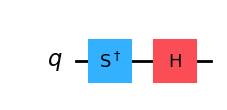

In [44]:
# --- Solution 6 ---------------------------------------------------------
sol6 = QuantumCircuit(1)
sol6.sdg(0)       # S† : |+i> -> |+>,  |-i> -> |->
sol6.h(0)         # H  : |+> -> |0>,   |-> -> |1>
check_6(sol6)
sol6.draw("mpl")

---
## 14 · One-page summary (for your repo README / revision)

- **Pauli group:** $\{\pm1,\pm i\}\times\{I,X,Y,Z\}^{\otimes n}$; closed under multiplication; every element Hermitian-up-to-phase, unitary, squares to $\pm I$.
- **Qiskit label rule:** rightmost char ↔ qubit 0; `Pauli("XZ")` ↔ $X\otimes Z$ ↔ X on q1, Z on q0.
- **Internals:** `(z, x, phase)`; $P=(-i)^{\text{phase}+\sum z_kx_k}Z^{\mathbf z}X^{\mathbf x}$.
- **Products:** `A.dot(B)` / `A @ B` = $AB$; `A.compose(B)` = $BA$. **Tensor:** `A.tensor(B)` / `A ^ B` = $A\otimes B$; `A.expand(B)` = $B\otimes A$.
- **Commutation:** count clashing positions; even ⇒ commute.
- **Measurement:** Z directly; X after `H`; Y after `Sdg`,`H`. $\Pr(\pm1)=(1\pm\langle P\rangle)/2$.
- **Decomposition:** $c_P=\operatorname{Tr}(PM)/2^n$; `SparsePauliOp.from_operator`.
- **Next:** Task 1.2 — *Apply quantum operations* (gates from the circuit library and `QuantumCircuit`).